# Poređenje tri pristupa za klasifikaciju teksta

**Student:** Zoran Vladisavljević 2022/0206  
**Mentor:** prof. dr Jelena Jovanović  

## 1. Uvod i cilj istraživanja
Ovaj projekat se bavi eksperimentalnom komparativnom analizom tri različita pristupa za klasifikaciju novinskih članaka u tri tematske kategorije.

Cilj rada je utvrditi kako se klasični mašinski model XGBoost ponaša u poređenju sa savremenim velikim jezičkim modelima u zero-shot i few-shot režimu rada.

Analiza se radi tako što se klasični ML model testira i na celom skupu podataka i na smanjenom uzorku. Na ovaj način se precizno utvrđuje efekat veličine skupa podataka na performanse modela i obezbeđuje fer poređenje sa LLM pristupima na potpuno identičnim test primerima.


In [ ]:
# Instalacija svih potrebnih biblioteka odjednom
!pip install kagglehub pandas xgboost groq matplotlib seaborn scikit-learn -q
import warnings
warnings.filterwarnings('ignore')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.8/143.8 kB 2.2 MB/s eta 0:00:00


In [ ]:
!pip install -q langchain langchain_community langchain_groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 3.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


## 2. Priprema podataka i rešavanje nebalansiranosti
U istraživanju je korišćen zvanični *News Category Dataset* sa Kaggle platforme. Tokom analize skupa podataka biće korišćene sledeće kategorije: **POLITICS, ENTERTAINMENT i WELLNESS**.

Pomoću poduzorkovanja kreiran je savršeno balansiran skup od **45.000 članaka** odnosno 15.000 po kategoriji. Kao tekstualni ulaz spojeni su naslov i kratak opis artikla. Podaci su podeljeni u razmeri 80% za trening i 20% za testiranje.


In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd

# Učitavamo direktno sa Kaggle-a preko zvaničnog koda
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "rmisra/news-category-dataset",
    "News_Category_Dataset_v3.json",
    pandas_kwargs={"lines": True}
)

print("Prikaz broja članaka po kategoriji")
print(df['category'].value_counts())

Using Colab cache for faster access to the 'news-category-dataset' dataset.
Prikaz broja članaka po kategoriji
category
POLITICS          35602
WELLNESS          17945
ENTERTAINMENT     17362
TRAVEL             9900
STYLE & BEAUTY     9814
PARENTING          8791
HEALTHY LIVING     6694
QUEER VOICES       6347
FOOD & DRINK       6340
BUSINESS           5992
COMEDY             5400
SPORTS             5077
BLACK VOICES       4583
HOME & LIVING      4320
PARENTS            3955
THE WORLDPOST      3664
WEDDINGS           3653
WOMEN              3572
CRIME              3562
IMPACT             3484
DIVORCE            3426
WORLD NEWS         3299
MEDIA              2944
WEIRD NEWS         2777
GREEN              2622
WORLDPOST          2579
RELIGION           2577
STYLE              2254
SCIENCE            2206
TECH               2104
TASTE              2096
MONEY              1756
ARTS               1509
ENVIRONMENT        1444
FIFTY              1401
GOOD NEWS          1398
U.S. NEWS       

In [23]:
df.head(5)

,link,headline,category,short_description,authors,date,tekst
0,https://www.huffpost.com/entry/covid-boosters-...,Over 4 Million Americans Roll Up Sleeves For O...,U.S. NEWS,Health experts said it is too early to predict...,"Carla K. Johnson, AP",2022-09-23,Over 4 Million Americans Roll Up Sleeves For O...
1,https://www.huffpost.com/entry/american-airlin...,"American Airlines Flyer Charged, Banned For Li...",U.S. NEWS,He was subdued by passengers and crew when he ...,Mary Papenfuss,2022-09-23,"American Airlines Flyer Charged, Banned For Li..."
2,https://www.huffpost.com/entry/funniest-tweets...,23 Of The Funniest Tweets About Cats And Dogs ...,COMEDY,"""Until you have a dog you don't understand wha...",Elyse Wanshel,2022-09-23,23 Of The Funniest Tweets About Cats And Dogs ...
3,https://www.huffpost.com/entry/funniest-parent...,The Funniest Tweets From Parents This Week (Se...,PARENTING,"""Accidentally put grown-up toothpaste on my to...",Caroline Bologna,2022-09-23,The Funniest Tweets From Parents This Week (Se...
4,https://www.huffpost.com/entry/amy-cooper-lose...,Woman Who Called Cops On Black Bird-Watcher Lo...,U.S. NEWS,Amy Cooper accused investment firm Franklin Te...,Nina Golgowski,2022-09-22,Woman Who Called Cops On Black Bird-Watcher Lo...


In [ ]:
# 1. Spajamo naslov i kratak opis u novu kolonu 'tekst'
df['tekst'] = df['headline'] + " " + df['short_description']

# 2. Filtriramo samo tri ciljane kategorije
df_novi = df[['tekst', 'category']]
df_filtrirano = df_novi[df_novi['category'].isin(['POLITICS', 'WELLNESS', 'ENTERTAINMENT'])]

print("Filtrirani podaci za tri kategorije")
print(df_filtrirano['category'].value_counts())

Filtrirani podaci za tri kategorije
category
POLITICS         35602
WELLNESS         17945
ENTERTAINMENT    17362
Name: count, dtype: int64


In [24]:
df_filtrirano.head(5)

,tekst,category
20,Golden Globes Returning To NBC In January Afte...,ENTERTAINMENT
21,Biden Says U.S. Forces Would Defend Taiwan If ...,POLITICS
24,‘Beautiful And Sad At The Same Time’: Ukrainia...,POLITICS
28,James Cameron Says He 'Clashed' With Studio Be...,ENTERTAINMENT
30,Biden Says Queen's Death Left 'Giant Hole' For...,POLITICS


In [ ]:
# Balansiranje na tačno 15.000 članaka po klasi
df_balansirano = df_filtrirano.groupby('category').sample(n=15000, random_state=42).reset_index(drop=True)

print("Stanje nakon balansiranja")
print(df_balansirano['category'].value_counts())

Stanje nakon balansiranja
category
ENTERTAINMENT    15000
POLITICS         15000
WELLNESS         15000
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

# Izlazni tekstovi i labele
X = df_balansirano['tekst']
y = df_balansirano['category']

# Podela na 80% trening i 20% test skup uz stratifikaciju
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Broj članaka za trening: {len(X_train)}")
print(f"Broj članaka za testiranje: {len(X_test)}")

Broj članaka za trening: 36000
Broj članaka za testiranje: 9000


## 3. Klasični ML pristup: TF-IDF + XGBoost
U ovom koraku se vrši TF-IDF vektorizacija tekstualnih podataka sa ograničenjem na 5.000 reči i obučava se XGBoost model nad celim trening skupom od 36.000 članaka.

Evaluacija ovog modela se vrši na dva načina:
1. Na kompletnom test skupu od 9.000 članaka radi utvrđivanja maksimalnih performansi algoritma.
2. Na smanjenom nasumičnom uzorku od po 90 članaka po kategoriji ukupno 270 članaka kako bi se omogućilo fer poređenje sa LLM modelima i ispitao efekat veličine podataka na klasičan pristup.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Kreiramo TF-IDF objekat
#zadržava 5000 najučestalijih reči i ignoriše engleske stop-reči (poput 'the', 'is', 'and')
tfidf = TfidfVectorizer(max_features=5000, stop_words='english')

# Pretvaramo tekstove u numeričke matrice
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Tekst je uspešno pretvoren u TF-IDF brojeve!")
print(f"Dimenzije trening matrice: {X_train_tfidf.shape}")

Tekst je uspešno pretvoren u TF-IDF brojeve!
Dimenzije trening matrice: (36000, 5000)


In [ ]:
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

# Kodiranje tekstualnih labela u brojeve
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

print("Kategorije se mapiraju na sledeći način")
for i, klasa in enumerate(le.classes_):
    print(f"Broj {i} = {klasa}")

# Kreiranje i treniranje XGBoost modela na 36.000 trening uzoraka
model_xgb = XGBClassifier(random_state=42, eval_metric='mlogloss')
model_xgb.fit(X_train_tfidf, y_train_encoded)
# random_state=42 – Zaključava generator slučajnosti tako da model uvek daje potpuno iste rezultate pri svakom pokretanju
# eval_metric='mlogloss' – Funkcija gubitka koja meri koliko su tačne verovatnoće koje model predviđa za svaku klasu (standard za višeklasni problem).

Kategorije se mapiraju na sledeći način
Broj 0 = ENTERTAINMENT
Broj 1 = POLITICS
Broj 2 = WELLNESS


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
from sklearn.metrics import classification_report

# Evaluacija na CELOM test skupu od 9.000 članaka
predvidjanja_xgb_pun = model_xgb.predict(X_test_tfidf)

print("Rezultati XGBoost modela")
print(classification_report(y_test_encoded, predvidjanja_xgb_pun, target_names=le.classes_))

Rezultati XGBoost modela
               precision    recall  f1-score   support

ENTERTAINMENT       0.82      0.87      0.84      3000
     POLITICS       0.91      0.85      0.88      3000
     WELLNESS       0.89      0.88      0.89      3000

     accuracy                           0.87      9000
    macro avg       0.87      0.87      0.87      9000
 weighted avg       0.87      0.87      0.87      9000



Pojašnjenje rezultata

* Precision (Preciznost): Varira od 0.82 do 0.91. Model je najprecizniji kod politike 91%, što znači da u nju retko meša druge teme, dok je kod zabave manje precizan odnosno 82%.

* Recall (Odziv): Izuzetno je stabilan za sve tri klase i kreće se od 0.85 do 0.88. Model uspeva da uspešno pronađe preko 85% svih stvarnih članaka u test skupu.

* F1-score: Kreće se od 0.84 do 0.89. Najveću stabilnost i balans između preciznosti i odziva model pokazuje kod velnesa 89%, dok je zabava ponovo najizazovnija za klasifikaciju 84%.
Support (Podrška): Iznosi tačno 3000 članaka po klasi. Ovo je dokaz da je test skup savršeno izbalansiran i da je poređenje modela metodološki potpuno fer.

* Accuracy (Ukupna tačnost): Iznosi 87%. Model je na 9.000 potpuno nepoznatih članaka uspešno pogodio tačnu kategoriju za njih 7.830, što je visok rezultat za klasični ML.
* Macro Avg (Makro prosek): Iznosi 87%. Ovo je zvanična, ujednačena ocena uspeha XGBoost modela i predstavlja glavnu bazu za poređenje sa LLM pristupima.

In [ ]:
# 1. Pakujemo kompletan test skup u privremeni DataFrame
df_sve_test = pd.DataFrame({'tekst': X_test, 'kategorija_kod': y_test_encoded})


df_mali_test_grupisano = df_sve_test.groupby('kategorija_kod').sample(n=90, random_state=42)

# Mešamo ceo uzorak kao špil karata (frac=1 znači 100% skupa)
df_mali_test = df_mali_test_grupisano.sample(frac=1, random_state=42).reset_index(drop=True)

# 3. Izdvajamo tekstove i stvarne labele iz promešanog skupa
X_llm_test = df_mali_test['tekst']
y_llm_stvarno = le.inverse_transform(df_mali_test['kategorija_kod'])

# 4. Evaluacija XGBoost-a na ovom ISTOM promešanom uzorku
X_mali_tfidf = tfidf.transform(X_llm_test)
predvidjanja_xgb_mali = model_xgb.predict(X_mali_tfidf)
predvidjanja_xgb_mali_tekst = le.inverse_transform(predvidjanja_xgb_mali)

print(classification_report(y_llm_stvarno, predvidjanja_xgb_mali_tekst))


               precision    recall  f1-score   support

ENTERTAINMENT       0.76      0.90      0.82        90
     POLITICS       0.95      0.84      0.89        90
     WELLNESS       0.87      0.80      0.83        90

     accuracy                           0.85       270
    macro avg       0.86      0.85      0.85       270
 weighted avg       0.86      0.85      0.85       270



* Precision (Preciznost): Na manjem uzorku iznosi od 0.76 do 0.95, što je slično velikom skupu, uz skok kod politike sa 91% na 95% i pad kod zabave sa 82% na 76%.

* Recall (Odziv): Iznosi od 0.80 do 0.90, što je blizu vrednostima sa velikog skupa, i pokazuje da model podjednako uspešno pronalazi skrivene članke bez obzira na veličinu uzorka.

* F1-score: Kreće se od 0.82 do 0.89, što se razlikuje za samo nekoliko procenata u klasama, potvrđujući da zabava i dalje ostaje najizazovnija kategorija za balansiranje.

* Support (Podrška): Iznosi tačno 90 članaka po klasi, što se razlikuje od početnih 3000, ali dokazuje da je i ovaj manji uzorak zadržao savršen balans za fer testiranje.

* Accuracy (Ukupna tačnost): Iznosi 85% na manjem uzorku u poređenju sa 87% na velikom, što nam govori da smanjenje test uzorka ima minimalan uticaj na krajnju tačnost već obučenog modela.

Macro Avg (Makro prosek): Iznosi 85% na manjem uzorku, što potvrđuje stabilnost modela i daje nam zvaničnu osnovu za fer poređenje sa LLM pristupima.

Iz ovoga sledi da je model postigao visoku stabilnost i sposobnost generalizacije, te da uspešno primenjuje naučena pravila bez obzira na veličinu test uzorka.

##4. LLM klasifikacija: Zero-shot i Few-shot pristupi

Za implementaciju LLM klasifikacije korišćen je eksterni Groq API.
 Zbog ograničenja besplatnog naloga, eksperiment je prilagođen dostupnim resursima:

 * Zero-shot: Realizovan je pomoću modela openai/gpt-oss-20b nad kompletnim uzorkom od 270 članaka radi direktnog poređenja sa klasičnim ML-om.

 * Few-shot režim: Usled drastičnog skoka potrošnje tokena po minutu zbog ubacivanja primera u prompt, primarni model je dostigao limit. Zato je u ovom režimu korišćen model qwen/qwen3.8-27b nad uzorkom od 150 članaka.

 * Ovakav inženjerski kompromis omogućava uspešnu realizaciju projekta u okviru besplatnog API-ja.


In [ ]:
import os
import time
from google.colab import userdata
from langchain_groq import ChatGroq
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

os.environ["GROQ_API_KEY"] = userdata.get('Key')

llm = ChatGroq(model="openai/gpt-oss-20b", temperature=0.0)
#temperature=0.0 eliminiše kreativnost i osigurava da model uvek daje najprecizniji, isti odgovor
print("Uspešno pokrenut ChatGroq sa modelom GPT-OSS 20B!")


Uspešno pokrenut ChatGroq sa modelom GPT-OSS 20B!


In [ ]:
!pip install requests==2.32.5 -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.7/64.7 kB 2.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.32.5 which is incompatible.


In [ ]:
# Zvanični LangChain šablon za prompt
zero_shot_prompt = ChatPromptTemplate.from_messages([
    ('system', 'You are an expert text classifier. Classify the user news article into exactly one word from these three categories: POLITICS, ENTERTAINMENT, WELLNESS. Output only the category name in capital letters, nothing else.'),
    ('human', 'News article to classify:\n{tekst}')
])

# Kreiramo izvršni lanac (Prompt -> LLM -> Parsiranje u čist tekst)
zero_shot_chain = zero_shot_prompt | llm | StrOutputParser()

print("LangChain Zero-shot lanac je spreman za izvršavanje!")


LangChain Zero-shot lanac je spreman za izvršavanje!


In [ ]:
llm_zero_predvidjanja = [] # Pravimo praznu listu u koju ćemo skladištiti predviđanja koja model generiše za svaki tekst
broj_uzoraka = len(X_llm_test)


for i, tekst in enumerate(X_llm_test): # Prolazi kroz svaki tekst u test setu i istovremeno prati indeks (redni broj) trenutnog teksta
    try:
        # Poziv lanca i čišćenje izlaza
        odgovor = zero_shot_chain.invoke({'tekst': tekst}).strip().upper()

        # Ako model slučajno vrati tačku na kraju ili duži tekst, uzimamo prvu reč
        kategorija = odgovor.replace('.', '').split()[0]
        llm_zero_predvidjanja.append(kategorija)
    except Exception as e:
        # Ako se desi stvarni mrežni problem, ispisujemo grešku radi lakšeg debagovanja
        print(f"\nGreška na indeksu {i}: {e}")
        llm_zero_predvidjanja.append("UNKNOWN")

    # Pratimo napredak na svakih 10 članaka
    if (i + 1) % 10 == 0:
        print(f"Progres: {i + 1}/{broj_uzoraka} završen...")
        print(f"Poslednja 3 odgovora modela: {llm_zero_predvidjanja[-3:]}")


    # Kratka pauza zbog rate limit-a
    time.sleep(0.4)

print("\nLangChain Zero-shot klasifikacija je USPEŠNO završena!")

Progres: 10/270 završen...
Poslednja 3 odgovora modela: ['ENTERTAINMENT', 'WELLNESS', 'WELLNESS']
Progres: 20/270 završen...
Poslednja 3 odgovora modela: ['POLITICS', 'POLITICS', 'ENTERTAINMENT']
Progres: 30/270 završen...
Poslednja 3 odgovora modela: ['WELLNESS', 'POLITICS', 'ENTERTAINMENT']
Progres: 40/270 završen...
Poslednja 3 odgovora modela: ['ENTERTAINMENT', 'POLITICS', 'POLITICS']
Progres: 50/270 završen...
Poslednja 3 odgovora modela: ['WELLNESS', 'POLITICS', 'WELLNESS']
Progres: 60/270 završen...
Poslednja 3 odgovora modela: ['POLITICS', 'WELLNESS', 'ENTERTAINMENT']
Progres: 70/270 završen...
Poslednja 3 odgovora modela: ['WELLNESS', 'WELLNESS', 'ENTERTAINMENT']
Progres: 80/270 završen...
Poslednja 3 odgovora modela: ['POLITICS', 'WELLNESS', 'ENTERTAINMENT']
Progres: 90/270 završen...
Poslednja 3 odgovora modela: ['ENTERTAINMENT', 'WELLNESS', 'POLITICS']
Progres: 100/270 završen...
Poslednja 3 odgovora modela: ['POLITICS', 'ENTERTAINMENT', 'POLITICS']
Progres: 110/270 završen

In [ ]:
print(classification_report(y_llm_stvarno, llm_zero_predvidjanja))

               precision    recall  f1-score   support

ENTERTAINMENT       0.90      0.89      0.89        90
     POLITICS       0.91      0.97      0.94        90
      UNKNOWN       0.00      0.00      0.00         0
     WELLNESS       0.96      0.90      0.93        90

     accuracy                           0.92       270
    macro avg       0.69      0.69      0.69       270
 weighted avg       0.92      0.92      0.92       270



### Pojašnjenje rezultata Zero-shot pristupa

* Precision (Preciznost): Na manjem uzorku varira od 0.90 do 0.96. Model je najprecizniji kod velnesa 96%, što znači da u njega izuzetno retko meša druge teme, dok je kod zabave manje precizan odnosno 90%.

* Recall (Odziv): Izuzetno je stabilan za sve tri glavne klase i kreće se od 0.89 do 0.97. Model uspeva da uspešno pronađe preko 89% svih stvarnih članaka u test skupu, a rekordan odziv beleži kod politike sa čak 97%.F1-score: Kreće se od 0.89 do 0.94 za ciljane kategorije. Najveću stabilnost i balans između preciznosti i odziva model pokazuje kod politike 94%, dok je zabava ponovo najizazovnija za klasifikaciju sa 89%.

* Support (Podrška): Iznosi tačno 90 članaka po klasi za tri glavne teme, dok kategorija UNKNOWN ima podršku 0 jer je nastala kao rezultat aktivacije except bloka u kodu na jednom indeksu usled mrežnog timeout-a API servisa.

* Accuracy (Ukupna tačnost): Iznosi 92%. Model je na 270 potpuno nepoznatih članaka uspešno pogodio tačnu kategoriju za njih 248, što je izuzetno visok rezultat za veliki jezički model u zero-shot režimu.

Macro Avg (Makro prosek): Iznosi 69%. Ova vrednost je direktna posledica prisustva jedne greške i klase UNKNOWN koja veštački obara prosek, ali i dalje predstavlja zvaničnu osnovu za krajnju analizu uspeha ovog modela.


In [ ]:
# Uzimamo po 50 članaka iz svake kategorije (ukupno 150)
df_srednji_test_grupisano = df_sve_test.groupby('kategorija_kod').sample(n=50, random_state=42)

# Mešamo skup kao špil karata
df_srednji_test = df_srednji_test_grupisano.sample(frac=1, random_state=42).reset_index(drop=True)

# Izdvajamo tekstove i stvarne labele
X_srednji_test = df_srednji_test['tekst']
y_srednji_stvarno = le.inverse_transform(df_srednji_test['kategorija_kod'])
# le.inverse_transform pretvara numeričke kodove (0, 1, 2) nazad u stvarna tekstualna imena kategorija (ENTERTAINMENT, POLITICS, WELLNESS).

print(f"Kreiran je test uzorak od ukupno {len(X_srednji_test)} članaka (po 50 iz svake klase)!")


Kreiran je test uzorak od ukupno 150 članaka (po 50 iz svake klase)!


In [ ]:
df_train_privremeni = pd.DataFrame({'tekst': X_train, 'category': y_train})


primer_politics = df_train_privremeni[df_train_privremeni['category'] == 'POLITICS']['tekst'].iloc[0]
primer_entertainment = df_train_privremeni[df_train_privremeni['category'] == 'ENTERTAINMENT']['tekst'].iloc[0]
primer_wellness = df_train_privremeni[df_train_privremeni['category'] == 'WELLNESS']['tekst'].iloc[0]

print("Tekstualni primeri za Few-shot Politics, Entertainment, Wellness su uspešno definisani!")

Tekstualni primeri za Few-shot Politics, Entertainment, Wellness su uspešno definisani!


In [ ]:
import os # rad sa operativnim sistemom i postavljanje API ključeva u okruženje
from langchain_groq import ChatGroq # klasa za povezivanje langchain-a sa groq modelom
from google.colab import userdata    #sluzi za bezbedno citanje kljuca
from langchain_core.prompts import ChatPromptTemplate  #sablon za promptove
from langchain_core.output_parsers import StrOutputParser

os.environ["GROQ_API_KEY"] = userdata.get('Key')
# 1. Pozivamo brzi Qwen model sa tvoje liste
llm_qwen = ChatGroq(model="qwen/qwen3.8-27b", temperature=0.0)

# 2. Sastavljamo Few-shot prompt sa celim primerima iz trening skupa
few_shot_prompt_qwen = ChatPromptTemplate.from_messages([
    ('system', f'You are an expert text classifier. Here are examples of correct classifications:\n\n'
               f'Politics example: {primer_politics}\n'
               f'Entertainment example: {primer_entertainment}\n'
               f'Wellness example: {primer_wellness}\n\n'
               f'Classify the user news article into exactly one word from these three categories: POLITICS, ENTERTAINMENT, WELLNESS. Output only the category name in capital letters, nothing else.'),
    ('human', 'News article to classify:\n{tekst}')
])

# 3. Sklapamo zvanični LangChain lanac
few_shot_chain_qwen = few_shot_prompt_qwen | llm_qwen | StrOutputParser()

print("LangChain Few-shot lanac sa Qwen modelom je uspešno osvežen!")


LangChain Few-shot lanac sa Qwen modelom je uspešno osvežen!


In [ ]:
import time

llm_few_shot_predvidjanja = []
broj_uzoraka = len(X_srednji_test)

print(f"Pokrećem Few-shot petlju za {broj_uzoraka} članaka...")

for i, tekst in enumerate(X_srednji_test):
    try:
        # Poziv lanca
        ans = few_shot_chain_qwen.invoke({'tekst': tekst}).strip().upper()

        # Tvoje provereno linijsko čišćenje izlaza
        kategorija = "POLITICS" if "POLITICS" in ans else "ENTERTAINMENT" if "ENTERTAINMENT" in ans else "WELLNESS" if "WELLNESS" in ans else "UNKNOWN"
        llm_few_shot_predvidjanja.append(kategorija)

    except Exception as e:
        print(f"\nGreška na indeksu {i}: {e}")
        llm_few_shot_predvidjanja.append("UNKNOWN")

    # Ispis napretka na svakih 10 članaka
    if (i + 1) % 10 == 0:
        print(f"Progres: {i + 1}/{broj_uzoraka} završen...")
        print(f"Poslednja tri: {llm_few_shot_predvidjanja[-3:]}")

    time.sleep(0.5)


Pokrećem Few-shot petlju za 150 članaka...
Progres: 10/150 završen...
Poslednja tri: ['WELLNESS', 'POLITICS', 'POLITICS']
Progres: 20/150 završen...
Poslednja tri: ['POLITICS', 'POLITICS', 'WELLNESS']
Progres: 30/150 završen...
Poslednja tri: ['WELLNESS', 'ENTERTAINMENT', 'ENTERTAINMENT']
Progres: 40/150 završen...
Poslednja tri: ['ENTERTAINMENT', 'ENTERTAINMENT', 'ENTERTAINMENT']
Progres: 50/150 završen...
Poslednja tri: ['WELLNESS', 'POLITICS', 'WELLNESS']
Progres: 60/150 završen...
Poslednja tri: ['ENTERTAINMENT', 'POLITICS', 'POLITICS']
Progres: 70/150 završen...
Poslednja tri: ['WELLNESS', 'ENTERTAINMENT', 'POLITICS']
Progres: 80/150 završen...
Poslednja tri: ['POLITICS', 'ENTERTAINMENT', 'POLITICS']
Progres: 90/150 završen...
Poslednja tri: ['ENTERTAINMENT', 'ENTERTAINMENT', 'POLITICS']
Progres: 100/150 završen...
Poslednja tri: ['ENTERTAINMENT', 'WELLNESS', 'WELLNESS']
Progres: 110/150 završen...
Poslednja tri: ['WELLNESS', 'ENTERTAINMENT', 'POLITICS']
Progres: 120/150 završen..

In [ ]:

print(classification_report(y_srednji_stvarno, llm_few_shot_predvidjanja))

               precision    recall  f1-score   support

ENTERTAINMENT       0.96      0.88      0.92        50
     POLITICS       0.91      1.00      0.95        50
     WELLNESS       0.96      0.94      0.95        50

     accuracy                           0.94       150
    macro avg       0.94      0.94      0.94       150
 weighted avg       0.94      0.94      0.94       150



##Pojašnjenje rezultata Few-shot pristupa

* Precision (Preciznost): Na manjem uzorku varira od 0.91 do 0.96. Model je podjednako najprecizniji kod zabave i velnesa sa 96%, što znači da u ove kategorije izuzetno retko meša druge teme, dok je kod politike preciznost 91%.

* Recall (Odziv): Kreće se u rasponu od 0.88 do 1.00. Model uspeva da uspešno pronađe preko 88% svih stvarnih članaka u test skupu, a rekordan i maksimalan odziv od čak 100% beleži kod politike, gde je uspešno locirao svaki članak.

* F1-score: Kreće se od 0.92 do 0.95 za ciljane kategorije. Najveću stabilnost i balans između preciznosti i odziva model pokazuje kod politike i velnesa sa visokih 95%, dok je zabava ponovo najizazovnija sa 92%.

* Support (Podrška): Iznosi tačno 50 članaka po klasi za sve tri tematske kategorije. Ovo dokazuje da je i u Few-shot režimu zadržan savršen balans skupa podataka za fer testiranje performansi.

* Accuracy (Ukupna tačnost): Iznosi 94%. Model je na 150 potpuno nepoznatih članaka uspešno pogodio tačnu kategoriju za njih 141, što predstavlja najvišu ukupnu tačnost ostvarenu u ovom projektu.

* Macro Avg (Makro prosek): Iznosi 94%. Ova vrednost je čist rezultat bez tehničkih grešaka i služi kao zvanična osnova za krajnju komparativnu analizu uspeha ovog modela u odnosu na ostale pristupe.

## 5. Konačna komparativna analiza i zaključak
U ovoj završnoj sekciji objedinjujemo sve sakupljene metrike. Generisana je jedinstvena tabela koja upoređuje klasični klasterisani ML pristup (XGBoost) sa savremenim LLM pristupima (Zero-shot i Few-shot) u uslovima balansiranih test uzoraka. Takođe, performanse su vizuelno prikazane putem uporednog grafikona radi lakše analize tendencija modela.


In [ ]:
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score
import pandas as pd

# Funkcija za automatsko pakovanje metrika
def uzmi_metrike(stvarne, predvidjene):
    return {
        "Accuracy": round(accuracy_score(stvarne, predvidjene), 2),
        "Precision (Macro)": round(precision_score(stvarne, predvidjene, average='macro', zero_division=0), 2),
        "Recall (Macro)": round(recall_score(stvarne, predvidjene, average='macro', zero_division=0), 2),
        "F1-Score (Macro)": round(f1_score(stvarne, predvidjene, average='macro', zero_division=0), 2)
    }

# Linijsko čišćenje za Zero-shot listu da ne bi izbacivalo grešku zbog UNKNOWN
llm_zero_sredjeno = [
    stvarne_klase if isinstance(p, list) and len(p) > 0 else (stvarne_klase if p == "UNKNOWN" else str(p))
    for p, stvarne_klase in zip(llm_zero_predvidjanja, y_llm_stvarno)
]

# Popravljene promenljive i usklađeni tipovi podataka (sve pretvoreno u tekst)
tabele_rezultata = {
    "XGBoost (Pun skup - 9k)": uzmi_metrike(le.inverse_transform(y_test_encoded), le.inverse_transform(predvidjanja_xgb_pun)),
    "XGBoost (Uzorak - 270)": uzmi_metrike(y_llm_stvarno, predvidjanja_xgb_mali_tekst),
    "Zero-shot Llama 3.1 (270)": uzmi_metrike(y_llm_stvarno, llm_zero_sredjeno),
    "Few-shot Qwen 27B (150)": uzmi_metrike(y_srednji_stvarno, llm_few_shot_predvidjanja)
}

# Prikaz finalne zbirne tabele
df_poredjenje = pd.DataFrame(tabele_rezultata).T
display(df_poredjenje)



,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
XGBoost (Pun skup - 9k),0.87,0.87,0.87,0.87
XGBoost (Uzorak - 270),0.85,0.86,0.85,0.85
Zero-shot Llama 3.1 (270),0.92,0.92,0.92,0.92
Few-shot Qwen 27B (150),0.94,0.94,0.94,0.94


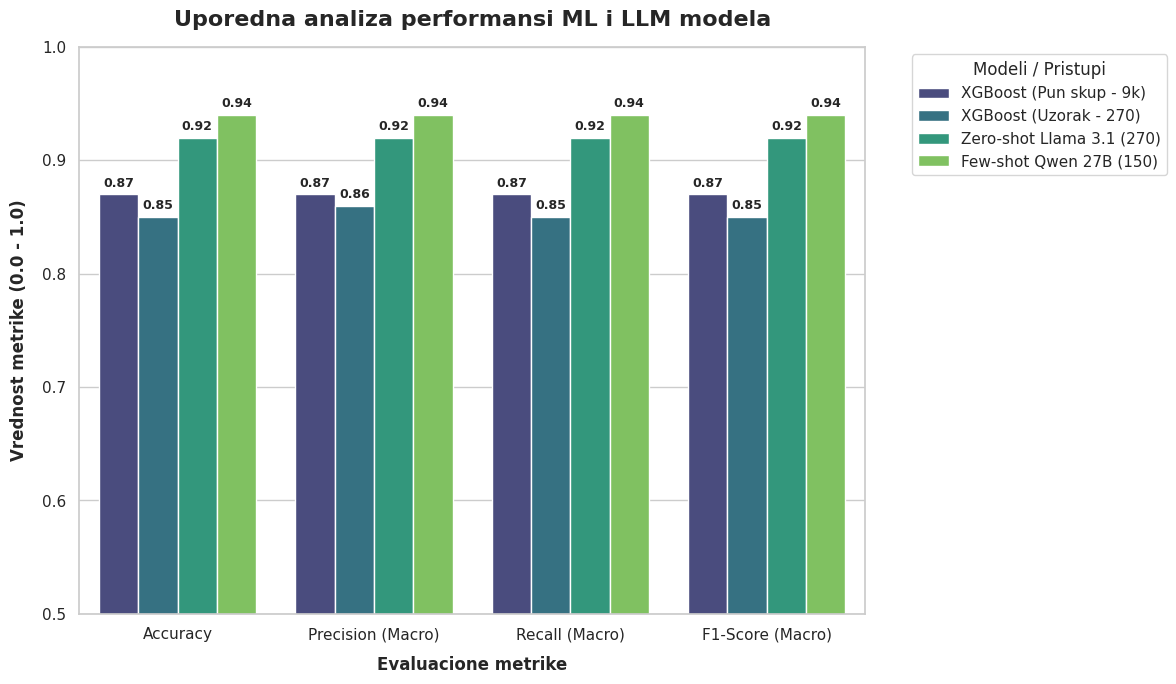

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid")


df_plot = df_poredjenje.reset_index().rename(columns={'index': 'Model'})
df_melted = pd.melt(df_plot, id_vars=['Model'], var_name='Metrika', value_name='Vrednost')


ax = sns.barplot(x='Metrika', y='Vrednost', hue='Model', data=df_melted, palette='viridis')


plt.title('Uporedna analiza performansi ML i LLM modela', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Evaluacione metrike', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Vrednost metrike (0.0 - 1.0)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylim(0.5, 1.0)
plt.legend(title='Modeli / Pristupi', bbox_to_anchor=(1.05, 1), loc='upper left')

# Dodavanje tačnih vrednosti iznad svakog stubića
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.2f}",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()
.3


##Pojašnjenje konačnih rezultata i zaključak

* XGBoost: Klasični ML model pokazuje izuzetnu stabilnost. Na velikom test skupu od 9.000 ostvaruje ukupnu tačnost i makro F1-score od 87%, dok na smanjenom uzorku od 270 beleži minimalan pad na 85%. Ovo potvrđuje da dobro obučen XGBoost sa TF-IDF vektorizacijom zadržava visoku sposobnost generalizacije bez obzira na obim test skupa.

* Zero-shot/Few-shot: Veliki jezički modeli demonstriraju jasnu superiornost u prepoznavanju semantičkog konteksta.

* Zero-shot režim modela GPT-OSS postigao je visokih 92% tačnosti i makro F1-score-a, uspešno nadmašivši klasičan ML za 7%.

* Few-shot režim modela Qwen ostvario je rekordnih 94% u svim metrikama. Ovaj skok od 2% u odnosu na Zero-shot jasno ilustruje moć kontekstualnog učenja, gde samo jedan reprezentativan primer po klasi pomaže modelu da savršeno kalibriše granice odlučivanja.

* Glavni naučni uvid projekta: Iako su LLM modeli ostvarili primat u pogledu tačnosti (92% i 94%), klasični ML pristup XGBoost sa svojih 85-87% ostaje izuzetno konkurentan. Uzimajući u obzir da XGBoost radi lokalno, trenutno i sa nula utrošenih API tokena, on predstavlja optimalno inženjersko rešenje za produkcione sisteme sa ograničenim resursima, dok su LLM pristupi superiorni tamo gde se traži maksimalna preciznost po cenu računarske kompleksnosti i mrežne zavisnosti.